In [118]:
import os
from dotenv import load_dotenv

from langchain_openai import AzureOpenAIEmbeddings

In [119]:
load_dotenv()

True

In [120]:
from langchain_community.document_loaders import TextLoader, DirectoryLoader

In [121]:
loader = DirectoryLoader(
    "docs",
    glob="**/*.txt",
    loader_cls=TextLoader)

In [122]:
documents = loader.load()

In [123]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [124]:
splitter = RecursiveCharacterTextSplitter(chunk_size=50, chunk_overlap=10)

chunks = splitter.split_documents(documents)

In [125]:
chunks

[Document(metadata={'source': 'docs\\long.txt'}, page_content='A very long text'),
 Document(metadata={'source': 'docs\\rag.txt'}, page_content="let's talk about rag")]

In [126]:
from langchain_community.vectorstores import FAISS

In [127]:
embeddings = AzureOpenAIEmbeddings(
    azure_deployment=os.environ.get("AZURE_OPENAI_EMBEDDING_DEPLOYMENT_NAME"),
    azure_endpoint=os.environ.get("AZURE_OPENAI_ENDPOINT"),
    api_key=os.environ.get("AZURE_OPENAI_API_KEY"),
    api_version=os.environ.get("AZURE_OPENAI_API_VERSION")
)

In [128]:
vectorstore = FAISS.from_documents(chunks, embeddings)

In [129]:
retriever = vectorstore.as_retriever()

In [130]:
from langchain_openai import AzureChatOpenAI

llm = AzureChatOpenAI(
    api_key = os.getenv("AZURE_OPENAI_API_KEY"),
    api_version=os.getenv("AZURE_OPENAI_API_VERSION"),
    azure_deployment = os.getenv("AZURE_OPENAI_DEPLOYMENT_NAME"),
    azure_endpoint= os.getenv("AZURE_OPENAI_ENDPOINT"),
)

In [131]:
llm.invoke("Hey")

AIMessage(content='Hi! What would you like to talk about or work on today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 7, 'total_tokens': 30, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}, 'latency_checkpoint': {'engine_tbt_ms': 8, 'engine_ttft_ms': 33, 'engine_ttlt_ms': 218, 'pre_inference_ms': 106, 'service_tbt_ms': 8, 'service_ttft_ms': 383, 'service_ttlt_ms': 562, 'user_visible_ttft_ms': 277}}, 'model_provider': 'openai', 'model_name': 'gpt-5.1-2025-11-13', 'system_fingerprint': None, 'id': 'chatcmpl-EXwnC2lfcyPJSJn5v2FyDyVnY4TWB', 'service_tier': 'default', 'prompt_filter_results': [{'prompt_index': 0, 'content_filter_results': {'hate': {'filtered': False, 'severity': 'safe'}, 'jailbreak': {'detected': False, 'filtered': False}

In [132]:
from langchain_classic.tools.retriever import create_retriever_tool

retriever_tool = create_retriever_tool(
    retriever,
    name="search_documents",
    description="Search the loaded documents for information relevant to the user's question.",
)

tools = [retriever_tool]
llm_with_tool = llm.bind_tools(tools)

In [133]:
llm_with_tool.invoke("what does the rag docs talk about")

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 28, 'prompt_tokens': 146, 'total_tokens': 174, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}, 'latency_checkpoint': {'engine_tbt_ms': 7, 'engine_ttft_ms': 37, 'engine_ttlt_ms': 233, 'pre_inference_ms': 81, 'service_tbt_ms': 6, 'service_ttft_ms': 362, 'service_ttlt_ms': 537, 'user_visible_ttft_ms': 281}}, 'model_provider': 'openai', 'model_name': 'gpt-5.1-2025-11-13', 'system_fingerprint': None, 'id': 'chatcmpl-EXwnESWf6rfCU9Yh5FckPCWOVeqi0', 'service_tier': 'default', 'prompt_filter_results': [{'prompt_index': 0, 'content_filter_results': {'hate': {'filtered': False, 'severity': 'safe'}, 'jailbreak': {'detected': False, 'filtered': False}, 'self_harm': {'filtered': False, 'severity': 'safe'

In [134]:
from pydantic import BaseModel
from typing_extensions import TypedDict, Annotated, Literal
from langchain.messages import HumanMessage,SystemMessage
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class AgentState(TypedDict):
    question: Annotated[list[AnyMessage], add_messages]
    documents: list[str]
    decision: str
    grade: str
    feedback: str
    answer: str
    retries: int

In [135]:
class RouteDecision(BaseModel):
    route: Literal["retrieve", "direct"]


def route_node(state: AgentState) -> str:
    router = llm.with_structured_output(RouteDecision)

    decision = router.invoke([
        SystemMessage(content=(
            "Decide whether the question needs information from the loaded "
            "documents. Return 'retrieve' if it does; otherwise return 'direct'."
        )),
        HumanMessage(content=state["question"]),
    ])

    return decision.route

In [136]:
def retriever_node(state: AgentState):
    question = state["question"]
    docs = retriever.invoke(question)
    context = "\n\n".join(doc.page_content for doc in docs)
    
    return {"documents": context}

In [137]:
def generate_node(state: AgentState):
    feedback = state.get("feedback", "")
    previous_answer = state.get("answer", "")

    response = llm.invoke([
        SystemMessage(content=(
            f"Answer using only this context:\n\n{state['documents']}\n\n"
            f"If revising a previous answer, address this feedback:\n{feedback}"
        )),
        HumanMessage(content=f"{state['question']} and the previous answer {previous_answer}"),
    ])

    return {"answer": response.content, "retries": state.get("retries", 0) + 1}

In [138]:
class Grade(BaseModel):
    suggest: Literal["yes", "no"]
    feedback: str


def grade_node(state: AgentState):
    grader_llm = llm.with_structured_output(Grade)

    response = grader_llm.invoke([
        SystemMessage(
            content=(
                "Evaluate whether the answer correctly answers the question "
                "and is supported by the provided context. Return 'yes' if it "
                "does; otherwise return 'no'."
            )
        ),
        HumanMessage(content=(
            f"Question: {state['question']}\n\n"
            f"Context: {state['documents']}\n\n"
            f"Answer: {state['answer']}"
        )),
    ])

    return {"grade": response.suggest, "feedback": response.feedback}

In [139]:
def direct_generate_node(state: AgentState):
    response = llm.invoke([
        SystemMessage(content="Answer the user's question directly."),
        HumanMessage(content=state["question"]),
    ])
    return {"answer": response.content}

In [ ]:
def critic(state: AgentState):
    if state['grade'] == "yes" or state["retries"] >=3 :
        return END
    return "generate"

In [141]:
# from langgraph.graph import StateGraph, START, END

# builder = StateGraph(AgentState)
# builder.add_node("retriever", retriever_node)
# builder.add_node("generate", generate_node)
# builder.add_node("grade", grade_node)

# builder.add_edge(START, "retriever")
# builder.add_edge("retriever", "generate")
# builder.add_edge("generate", "grade")
# builder.add_conditional_edges("grade", critic)

# graph = builder.compile()

In [142]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(AgentState)

builder.add_node("route", route_node)
builder.add_node("retriever", retriever_node)
builder.add_node("generate", generate_node)
builder.add_node("grade", grade_node)
builder.add_node("direct_generate", direct_generate_node)

builder.add_edge(START, "route")
builder.add_conditional_edges(
    "route",
    lambda state: state["route"],
    {
        "retrieve": "retriever",
        "direct": "direct_generate",
    },
)

builder.add_edge("retriever", "generate")
builder.add_edge("generate", "grade")
builder.add_conditional_edges("grade", critic)  # END if good; "generate" if not
builder.add_edge("direct_generate", END)

graph = builder.compile()

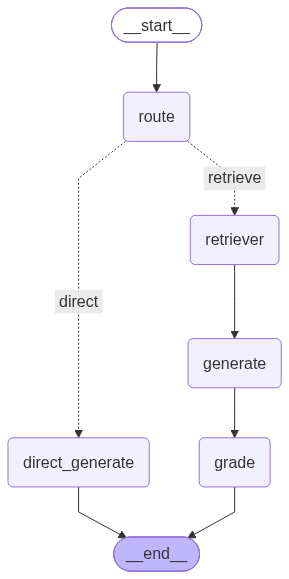

In [143]:
from IPython.display import display, Image

display(Image(graph.get_graph().draw_mermaid_png()))